In [46]:
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from pathlib import Path
from socket import gethostname
import seaborn as sns

host = gethostname()

if host == 'gcer-a100':
    font_path = '/home/dhester/.fonts/InterVariable.ttf'
elif host == 'ABE-BC546S3':
    font_path = r"C:\Users\dh2306\AppData\Local\Microsoft\Windows\Fonts\Inter-VariableFont_opsz,wght.ttf"
elif host == 'MacBookPro':
    font_path = '/Users/dak/Library/Fonts/Inter-VariableFont_opsz,wght.ttf'
else:
    raise NotImplementedError("Unknown host. Please set the Inter font path for this machine.")

font_manager.fontManager.addfont(font_path)
prop = font_manager.FontProperties(fname=font_path)

# plt.style.use('bmh')
plt.style.use('seaborn-v0_8-colorblind')
# plt.rcParams['axes.facecolor'] = 'white'
# plt.rcParams['axes.edgecolor'] = 'black'
# plt.rcParams['axes.linewidth'] = 0.5

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()
# plt.rcParams['mathtext.fontset'] = 'stix'

plt.rcParams.update({
    'mathtext.fontset': 'stix',
    'mathtext.default': 'it',
})


In [ ]:
lc_df = pd.read_csv('../runs/s2flow_lc_sampling_steps_sweep/lc_summary_metrics_all.csv')

# lc_df_reduced = lc_df.loc[lc_df['sampler'].isin(['s2', 'realesrgan', 'euler', 'naip']) & lc_df['steps'].isin([0, 1])]
# lc_df_reduced_mean = lc_df_reduced.groupby(['model', 'sampler', 'steps']).mean(numeric_only=True).reset_index()
# lc_df_reduced_std = lc_df_reduced.groupby(['model', 'sampler', 'steps']).std(numeric_only=True).reset_index()

# fancy_sampler_names = {
#     'euler': 'Euler',
#     'ddpm': 'DDPM',
#     'ddim': 'DDIM',
# }
# fancy_model_names = {
#     'segformer': 'SegFormer',
#     'deeplabv3plus': 'DeepLabV3+',
#     'unet': 'U-Net'
# }

# lc_df_reduced_mean['model'] = lc_df_reduced_mean['model'].map(fancy_model_names)
# lc_df_reduced_mean['model'] = pd.Categorical(
#     lc_df_reduced_mean['model'],
#     categories=['U-Net', 'DeepLabV3+', 'SegFormer'],
#     ordered=True
# )
# lc_df_reduced_std['model'] = lc_df_reduced_std['model'].map(fancy_model_names)
# lc_df_reduced_std['model'] = pd.Categorical(
#     lc_df_reduced_std['model'],
#     categories=['U-Net', 'DeepLabV3+', 'SegFormer'],
#     ordered=True
# )

# lc_df_reduced_mean['sampler'] = lc_df_reduced_mean['sampler'].map(fancy_sampler_names)
# lc_df_reduced_mean['sampler'] = pd.Categorical(
#     lc_df_reduced_mean['sampler'],
#     categories=['Sentinel-2', 'Real-ESRGAN', r'Euler ($T=1$)', 'NAIP'],
#     ordered=True
# )
# lc_df_reduced_std['sampler'] = lc_df_reduced_std['sampler'].map(fancy_sampler_names)
# lc_df_reduced_std['sampler'] = pd.Categorical(
#     lc_df_reduced_std['sampler'],
#     categories=['Sentinel-2', 'Real-ESRGAN', r'Euler ($T=1$)', 'NAIP'],
#     ordered=True
# )

# mapping = {
#     'model': 'Model',
#     'sampler': 'Input Data Source',
#     'macro_precision': "User's Accuracy (%)",
#     'macro_recall': "Producer's Accuracy (%)",
#     'macro_f1': 'F1 Score (%)',
#     'overall_accuracy': 'Overall Accuracy (%)',
# }
# reverse_mapping = {v: k for k, v in mapping.items()}
# lc_df_table = lc_df_reduced_mean.sort_values(['model', 'sampler'])[['model', 'sampler', 'macro_precision', 'macro_recall', 'macro_f1', 'overall_accuracy']]
# lc_df_table = lc_df_table.rename(columns=mapping)

# # convert to percent format
# for col in ["User's Accuracy (%)", "Producer's Accuracy (%)", 'F1 Score (%)', 'Overall Accuracy (%)']:
#     lc_df_table[col] = lc_df_table[col] * 100.0
#     lc_df_table[col] = lc_df_table[col].round(2)
#     lc_df_table[col] = lc_df_table[col].map(lambda x: f"{x:.2f}")
    
#     # now add std
#     std_col = lc_df_reduced_std.sort_values(['model', 'sampler'])[['model', 'sampler', reverse_mapping[col]]]
#     std_col = std_col.rename(columns={reverse_mapping[col]: 'std'})
#     std_col['std'] = std_col['std'] * 100.0
#     std_col['std'] = std_col['std'].round(2)
#     # make sure std_col has 2 decimal places
#     std_col['std'] = std_col['std'].map(lambda x: f"{x:.2f}")
    
#     # now combine
#     lc_df_table[col] = lc_df_table.apply(
#         lambda row: f"{row[col]} ± {std_col.loc[(std_col['model'] == row['Model']) & (std_col['sampler'] == row['Input Data Source']), 'std'].values[0]}",
#         axis=1
#     )

# lc_df_table
# lc_df_table.to_csv('../runs/s2flow_lc_sampling_steps_sweep/sampling_lc_summary_table.csv', index=False)

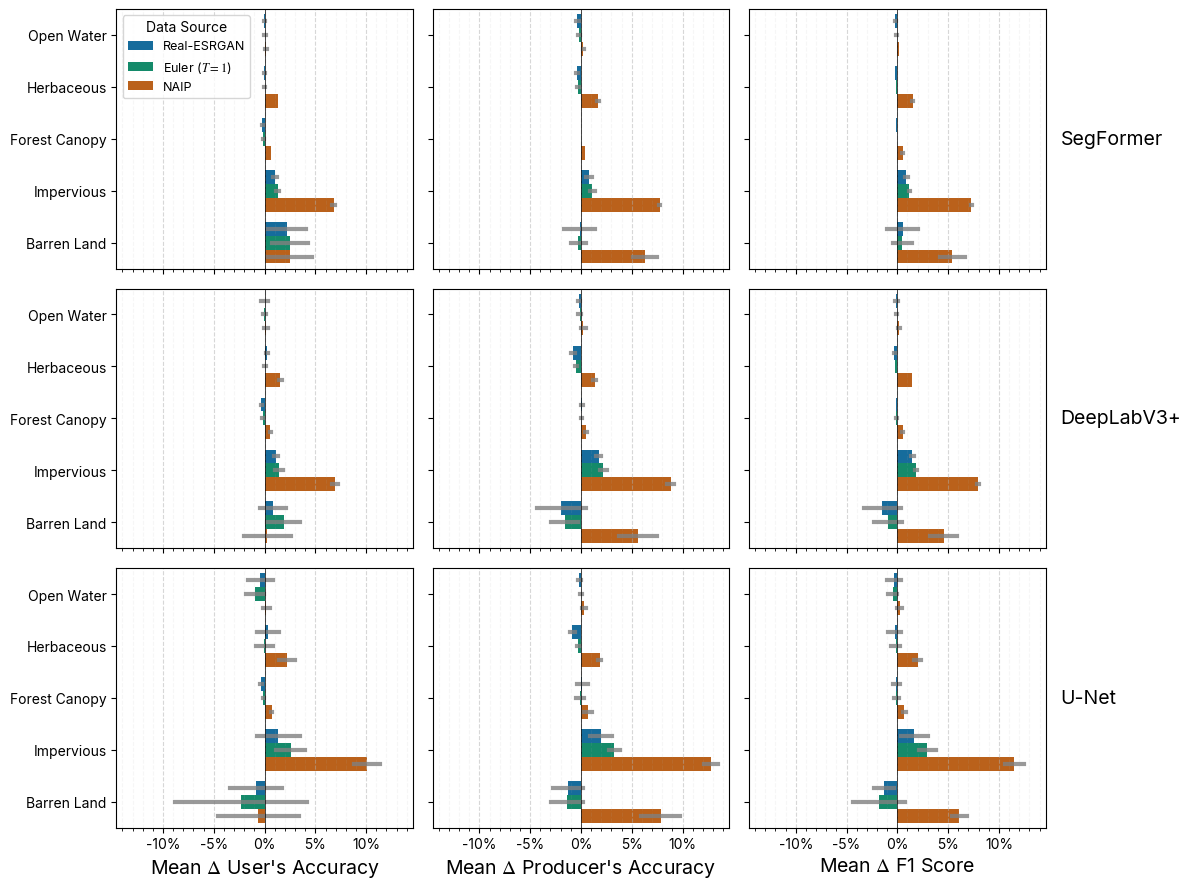

In [47]:

deltas = []
metrics = ['precision', 'recall', 'f1_score']

fancy_data_labels = {
    's2': 'Sentinel-2',
    'realesrgan': 'Real-ESRGAN',
    'euler': 'Euler ($T=1$)',
    'naip': 'NAIP',
}
fancy_metric_names = {
    'precision': 'User\'s Accuracy',
    'recall': 'Producer\'s Accuracy',
    'f1_score': 'F1 Score',
    # 'mean_iou': 'mIoU',
}

class_names = {
    1: 'Open Water',
    2: 'Herbaceous',
    3: 'Forest Canopy',
    4: 'Impervious',
    5: 'Barren Land',
}

fancy_model_names = {
    'segformer': 'SegFormer',
    'unet': 'U-Net',
    'deeplabv3plus': 'DeepLabV3+'
}

# colors = sns.color_palette('magma', n_colors=3)
colors = sns.color_palette(n_colors=3)
s2_color = 'black'
# colors = colors[1:]  # Exclude the first color for baseline

class_wise_metrics_df = pd.read_csv('../runs/s2flow_lc_sampling_steps_sweep/class_wise_metrics.csv')

for model in ['segformer', 'deeplabv3plus', 'unet']:
    model_df = class_wise_metrics_df[class_wise_metrics_df['model'] == model]
    
    # Isolate baseline (Sentinel-2)
    baseline = model_df[model_df['sampler'] == 's2'].set_index(['fold'])
    
    # Calculate difference for other samplers
    for sampler in ['realesrgan', 'euler', 'naip']:
        curr_sampler = model_df[model_df['sampler'] == sampler].set_index(['fold'])
        
        # Calculate delta for each class metric
        delta_df = curr_sampler.filter(like='class_') - baseline.filter(like='class_')
        delta_df = delta_df.reset_index()
        delta_df['sampler'] = sampler
        delta_df['model'] = model
        deltas.append(delta_df)

delta_master_df = pd.concat(deltas)

# 2. Plotting
fig, ax = plt.subplots(3, 3, figsize=(12, 9), sharex=True, sharey=True)

for i, model in enumerate(['segformer', 'deeplabv3plus', 'unet']):
    for j, metric in enumerate(['precision', 'recall', 'f1_score']):
        plot_df = delta_master_df[delta_master_df['model'] == model]
        
        # Melt for plotting
        melted = plot_df.melt(
            id_vars=['sampler', 'fold'],
            value_vars=[f'class_{k}_{metric}' for k in class_names.keys()],
            var_name='class_name',
            value_name='delta'
        )
        melted['class_name'] = melted['class_name'].apply(lambda x: class_names[int(x.split('_')[1])])
        melted['sampler_label'] = melted['sampler'].map(fancy_data_labels)

        sns.barplot(
            data=melted,
            y='class_name',
            x='delta',
            hue='sampler_label',
            palette=colors,
            ax=ax[i][j],
            errorbar='sd', 
            err_kws={
                'linewidth': 3,
                'alpha': 0.8,
                'color': 'gray'
                
            }
            # 'errorbar': 'sd',
            # 'errwidth': 1.5,
            # 'errcolor': 'gray'
        )
        
        # Scientific Styling
        ax[i][j].axvline(0, color=s2_color, linewidth=0.5, linestyle='-')
        ax[i][j].set_ylabel('')
        
        
        # if i == 0:
            # ax[0][j].set_title(fancy_model_names[model], fontsize=14, fontweight='bold')
        
        # Legend handling
        if i == 0 and j == 0:
            ax[i][j].legend(title='Data Source', loc='upper left', bbox_to_anchor=(0, 1), fontsize=9)
        else:
            ax[i][j].get_legend().remove()
    
        ax[i][j].set_xlabel('Mean $\\Delta$ ' + fancy_metric_names[metric], fontsize=14)
        ax[i][j].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: '{:.0%}'.format(x)))
        ax[i][j].grid(True, axis='x', linestyle='--', alpha=0.5)
        # use minor gridlines as well
        ax[i][j].xaxis.minorticks_on()
        ax[i, j].grid(True, axis='x', which='minor', linestyle='--', alpha=0.1)

    # show model name on right side of the rightmost plot
    ax[i][-1].text(1.05, 0.5, fancy_model_names[model], transform=ax[i][-1].transAxes, fontsize=14, fontweight='bold', va='center')

# center x = 0 lines
running_xmin, running_xmax = float('inf'), float('-inf')
for axis in ax.flatten():
    xmin, xmax = axis.get_xlim()
    running_xmin = min(running_xmin, xmin)
    running_xmax = max(running_xmax, xmax)

# use symmetric x limits for all plots
if abs(running_xmin) > abs(running_xmax):
    running_xmax = abs(running_xmin)
else:
    running_xmin = -abs(running_xmax)
for axis in ax.flatten():
    axis.set_xlim(running_xmin, running_xmax)

# fig.supxlabel('Change in Accuracy Compared to Sentinel-2', fontsize=14, y=0.02)

plt.tight_layout()
plt.show()

out_path = Path('../figures/sampling_lc_delta_comparison_2')
out_path.mkdir(parents=True, exist_ok=True)
for filetype in ['png', 'pdf']:
    fig.savefig(out_path / f'sampling_lc_delta_comparison.{filetype}', dpi=300 if filetype=='png' else None, bbox_inches='tight')

In [51]:
import numpy as np
import pandas as pd
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

models = ['unet', 'deeplabv3plus', 'segformer']
folds = [0, 1, 2, 3, 4]
class_names = {
    1: 'Open Water',
    2: 'Herbaceous',
    3: 'Forest Canopy',
    4: 'Impervious',
    5: 'Barren Land',
}
global_metrics = ['macro_f1'] #, 'overall_accuracy']
class_metrics = [f'class_{class_id}_f1_score' for class_id in class_names]

if 'lc_df' not in globals():
    lc_df = pd.read_csv('../runs/s2flow_lc_sampling_steps_sweep/lc_summary_metrics_all.csv')
if 'class_wise_metrics_df' not in globals():
    class_wise_metrics_df = pd.read_csv('../runs/s2flow_lc_sampling_steps_sweep/class_wise_metrics.csv')


def get_paired_rows(data, metrics, model_name):
    required = {'model', 'sampler', 'fold', *metrics}
    missing = required.difference(data.columns)
    if missing:
        raise KeyError(f'Missing columns: {sorted(missing)}')

    rows = data.loc[data['model'].eq(model_name)]
    baseline_mask = rows['sampler'].eq('s2')
    flow_mask = rows['sampler'].eq('euler')
    if 'steps' in rows.columns:
        baseline_mask &= rows['steps'].eq(0)
        flow_mask &= rows['steps'].eq(1)

    baseline = rows.loc[baseline_mask, ['fold', *metrics]]
    flow = rows.loc[flow_mask, ['fold', *metrics]]
    for label, frame in [('s2 baseline', baseline), ('euler flow', flow)]:
        if frame['fold'].duplicated().any():
            raise ValueError(f'{model_name} has duplicate {label} observations within a fold.')
        if sorted(frame['fold'].tolist()) != folds:
            raise ValueError(
                f'{model_name} {label} folds are {sorted(frame["fold"].tolist())}; '
                f'expected {folds}.'
            )

    paired = baseline.merge(
        flow,
        on='fold',
        how='inner',
        suffixes=('_s2', '_euler'),
        validate='one_to_one',
    ).sort_values('fold').reset_index(drop=True)
    if paired['fold'].tolist() != folds:
        raise ValueError(f'{model_name}: s2 and euler fold ordering does not align.')
    return paired


def summarize_pair(model_label, metric_label, paired, metric_column):
    baseline_values = paired[f'{metric_column}_s2'].to_numpy(dtype=float)
    flow_values = paired[f'{metric_column}_euler'].to_numpy(dtype=float)
    differences = flow_values - baseline_values
    test = ttest_rel(flow_values, baseline_values, alternative='two-sided')
    return {
        'Model': model_label,
        'Metric': metric_label,
        'Baseline Mean ± SD': f'{baseline_values.mean() * 100:.2f} ± {baseline_values.std(ddof=1) * 100:.2f}',
        'Euler Mean ± SD': f'{flow_values.mean() * 100:.2f} ± {flow_values.std(ddof=1) * 100:.2f}',
        'Mean Δ (pp)': differences.mean() * 100,
        't-stat': test.statistic,
        'p-value': test.pvalue,
    }


def apply_bh_adjustment(summary):
    summary = summary.copy()
    summary['BH adjusted p-value'] = multipletests(
        summary['p-value'].to_numpy(), method='fdr_bh'
    )[1]
    summary['Significant after BH (α = 0.05)'] = np.where(
        summary['BH adjusted p-value'] < 0.05, 'Yes', 'No'
    )
    return summary


# Global metrics by architecture, followed by a paired test on fold-level architecture means.
global_pairs = {
    model_name: get_paired_rows(lc_df, global_metrics, model_name)
    for model_name in models
}
global_rows = []
for model_name, paired in global_pairs.items():
    for metric_name in global_metrics:
        global_rows.append(summarize_pair(model_name, metric_name, paired, metric_name))

for metric_name in global_metrics:
    aggregate = pd.concat([
        paired.assign(model=model_name)
        for model_name, paired in global_pairs.items()
    ], ignore_index=True)
    aggregate = aggregate.groupby('fold', as_index=False).agg(
        baseline=(f'{metric_name}_s2', 'mean'),
        euler=(f'{metric_name}_euler', 'mean'),
        model_count=('model', 'nunique'),
    ).sort_values('fold').reset_index(drop=True)
    if aggregate['fold'].tolist() != folds or not aggregate['model_count'].eq(3).all():
        raise ValueError(f'{metric_name}: aggregate must contain all 3 models in each fold.')
    aggregate_pair = aggregate.rename(columns={
        'baseline': f'{metric_name}_s2',
        'euler': f'{metric_name}_euler',
    })
    global_rows.append(summarize_pair('All models (fold-averaged)', metric_name, aggregate_pair, metric_name))

global_summary = apply_bh_adjustment(pd.DataFrame(global_rows))[[
    'Model', 'Metric', 'Baseline Mean ± SD', 'Euler Mean ± SD', 'Mean Δ (pp)',
    't-stat', 'p-value', 'BH adjusted p-value', 'Significant after BH (α = 0.05)',
]]
print('Summary Table 1: Global metrics; BH correction is across all rows in this table.')
print(global_summary.to_string(index=False, float_format=lambda value: f'{value:.4g}'))


# Class-wise F1 tests by architecture and paired tests on fold-level architecture means.
class_pairs = {
    model_name: get_paired_rows(class_wise_metrics_df, class_metrics, model_name)
    for model_name in models
}
class_rows = []
for model_name, paired in class_pairs.items():
    for class_id, class_name in class_names.items():
        row = summarize_pair(model_name, class_name, paired, f'class_{class_id}_f1_score')
        baseline_values = paired[f'class_{class_id}_f1_score_s2'].to_numpy(dtype=float)
        flow_values = paired[f'class_{class_id}_f1_score_euler'].to_numpy(dtype=float)
        row['Folds Won (out of 5)'] = int(np.count_nonzero(flow_values > baseline_values))
        class_rows.append(row)

class_summary = apply_bh_adjustment(pd.DataFrame(class_rows)).rename(columns={
    'Metric': 'Class',
    'Baseline Mean ± SD': 'Baseline F1 (%)',
    'Euler Mean ± SD': 'Euler F1 (%)',
})[[
    'Model', 'Class', 'Baseline F1 (%)', 'Euler F1 (%)', 'Mean Δ (pp)',
    'Folds Won (out of 5)', 't-stat', 'p-value', 'BH adjusted p-value',
    'Significant after BH (α = 0.05)',
]]
print('\nSummary Table 2: Class-wise F1; BH correction is across all 15 model/class tests.')
print(class_summary.to_string(index=False, float_format=lambda value: f'{value:.4g}'))

aggregate_class_rows = []
for class_id, class_name in class_names.items():
    aggregate = pd.concat([
        paired[['fold', f'class_{class_id}_f1_score_s2', f'class_{class_id}_f1_score_euler']]
        .assign(model=model_name)
        for model_name, paired in class_pairs.items()
    ], ignore_index=True)
    aggregate = aggregate.groupby('fold', as_index=False).agg(
        baseline=(f'class_{class_id}_f1_score_s2', 'mean'),
        euler=(f'class_{class_id}_f1_score_euler', 'mean'),
        model_count=('model', 'nunique'),
    ).sort_values('fold').reset_index(drop=True)
    if aggregate['fold'].tolist() != folds or not aggregate['model_count'].eq(3).all():
        raise ValueError(f'{class_name}: aggregate must contain all 3 models in each fold.')

    aggregate_pair = aggregate.rename(columns={
        'baseline': f'class_{class_id}_f1_score_s2',
        'euler': f'class_{class_id}_f1_score_euler',
    })
    row = summarize_pair('All models (fold-averaged)', class_name, aggregate_pair, f'class_{class_id}_f1_score')
    row['Folds Won (out of 5)'] = int(np.count_nonzero(aggregate['euler'] > aggregate['baseline']))
    aggregate_class_rows.append(row)

aggregate_class_summary = apply_bh_adjustment(pd.DataFrame(aggregate_class_rows)).rename(columns={
    'Metric': 'Class',
    'Baseline Mean ± SD': 'Baseline F1 (%)',
    'Euler Mean ± SD': 'Euler F1 (%)',
})[[
    'Class', 'Baseline F1 (%)', 'Euler F1 (%)', 'Mean Δ (pp)',
    'Folds Won (out of 5)', 't-stat', 'p-value', 'BH adjusted p-value',
    'Significant after BH (α = 0.05)',
]]
print('\nSummary Table 3: Aggregate class-wise tests; BH correction is across 5 classes.')
print(aggregate_class_summary.to_string(index=False, float_format=lambda value: f'{value:.4g}'))


# One planned comparison: average all model-by-class scores within each fold first.
pooled_class_rows = []
for model_name, paired in class_pairs.items():
    for class_id in class_names:
        pooled_class_rows.append(pd.DataFrame({
            'fold': paired['fold'],
            'Lanczos': paired[f'class_{class_id}_f1_score_s2'],
            'Flow Matching': paired[f'class_{class_id}_f1_score_euler'],
        }))
pooled_class_scores = pd.concat(pooled_class_rows, ignore_index=True)
pooled_fold_scores = pooled_class_scores.groupby('fold', as_index=False).agg(
    Lanczos=('Lanczos', 'mean'),
    **{'Flow Matching': ('Flow Matching', 'mean')},
).sort_values('fold').reset_index(drop=True)
if pooled_fold_scores['fold'].tolist() != folds:
    raise ValueError(f'Pooled comparison folds are {pooled_fold_scores["fold"].tolist()}; expected {folds}.')

pooled_lanczos = pooled_fold_scores['Lanczos'].to_numpy(dtype=float)
pooled_flow = pooled_fold_scores['Flow Matching'].to_numpy(dtype=float)
pooled_difference = pooled_flow - pooled_lanczos
pooled_test = ttest_rel(pooled_flow, pooled_lanczos, alternative='two-sided')
pooled_comparison = pd.DataFrame([{
    'Comparison': 'Flow Matching vs Lanczos (all models and classes)',
    'Lanczos Mean ± SD (%)': f'{pooled_lanczos.mean() * 100:.2f} ± {pooled_lanczos.std(ddof=1) * 100:.2f}',
    'Flow Matching Mean ± SD (%)': f'{pooled_flow.mean() * 100:.2f} ± {pooled_flow.std(ddof=1) * 100:.2f}',
    'Mean Δ (pp)': pooled_difference.mean() * 100,
    'Flow Matching Wins (of 5 folds)': int(np.count_nonzero(pooled_difference > 0)),
    't-stat': pooled_test.statistic,
    'p-value': pooled_test.pvalue,
    'Significant at α = 0.05': 'Yes' if pooled_test.pvalue < 0.05 else 'No',
}])
print('\nSummary Table 4: Single pooled paired comparison (15 model-class scores averaged within each fold; N=5 pairs; no model/class post-hoc tests).')
print(pooled_comparison.to_string(index=False, float_format=lambda value: f'{value:.4g}'))

Summary Table 1: Global metrics; BH correction is across all rows in this table.
                     Model   Metric Baseline Mean ± SD Euler Mean ± SD  Mean Δ (pp)  t-stat  p-value  BH adjusted p-value Significant after BH (α = 0.05)
                      unet macro_f1       76.81 ± 0.50    76.89 ± 0.56      0.08071   0.216   0.8395               0.8395                              No
             deeplabv3plus macro_f1       77.45 ± 0.21    77.55 ± 0.40       0.1017  0.8467   0.4449               0.5932                              No
                 segformer macro_f1       77.94 ± 0.27    78.23 ± 0.23        0.289     3.5   0.0249              0.09962                              No
All models (fold-averaged) macro_f1       77.40 ± 0.19    77.56 ± 0.30       0.1571   1.286   0.2679               0.5358                              No

Summary Table 2: Class-wise F1; BH correction is across all 15 model/class tests.
        Model         Class Baseline F1 (%) Euler F1 (%)  Mean Δ (

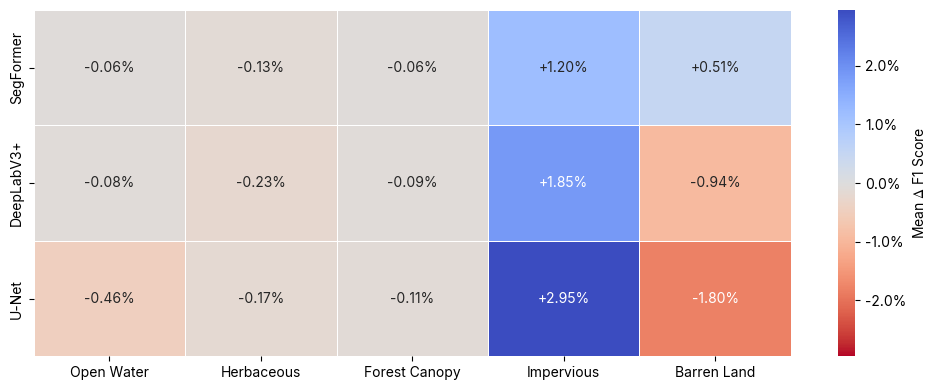

In [ ]:
f1_delta = delta_master_df.melt(
    id_vars=['model', 'sampler', 'fold'],
    value_vars=[f'class_{class_id}_f1_score' for class_id in class_names],
    var_name='class_id',
    value_name='delta_f1',
)
f1_delta['class_name'] = f1_delta['class_id'].map(
    lambda value: class_names[int(value.split('_')[1])]
)
f1_delta_mean = f1_delta.groupby(
    ['class_name', 'model', 'sampler'], observed=True
)['delta_f1'].mean().unstack(['model', 'sampler'])

classifier_order = ['segformer', 'deeplabv3plus', 'unet']
f1_delta_mean = f1_delta_mean.loc[
    list(class_names.values()),
    [(classifier, 'euler') for classifier in classifier_order],
].T
f1_delta_mean.index = ['SegFormer', 'DeepLabV3+', 'U-Net']

color_limit = max(f1_delta_mean.abs().to_numpy().max(), 0.01)
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(
    f1_delta_mean,
    ax=ax,
    cmap='coolwarm_r',
    center=0,
    vmin=-color_limit,
    vmax=color_limit,
    annot=True,
    fmt='+.2%',
    linewidths=0.5,
    cbar_kws={'label': r'Mean $\Delta$ F1 Score'},
)
ax.set_xlabel('')
ax.set_ylabel('')
ax.collections[0].colorbar.ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f'{value:+.1%}')
)
fig.tight_layout()

out_path = Path('../figures/sampling_lc_delta_heatmap/')
out_path.mkdir(parents=True, exist_ok=True)
for filetype in ['png', 'pdf']:
    fig.savefig(out_path / f'sampling_lc_delta_heatmap.{filetype}', dpi=300 if filetype=='png' else None, bbox_inches='tight')
